In [1]:
import tensorflow as tf
from keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
import tensorflow as tf
print("Num GPUs:", len(tf.config.list_physical_devices('GPU')))


Num GPUs: 1


**Build tf dataset**

In [3]:
IMAGE_SIZE = 224
BATCHES = 32
CHANNELS = 3

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    'crop_images',
    shuffle=True,
    batch_size=BATCHES,
    image_size = (IMAGE_SIZE, IMAGE_SIZE)
)

Found 41925 files belonging to 59 classes.


In [5]:
len(dataset)

1311

In [6]:
1312*32

41984

In [7]:
class_names = dataset.class_names
class_names

['Coffee___Healthy',
 'Coffee___Miner',
 'Coffee___Phoma',
 'Coffee___Rust',
 'Cotton___Aphids',
 'Cotton___Army_Worm',
 'Cotton___Bacterial_Blight',
 'Cotton___Healthy',
 'Cotton___Powdery_Mildew',
 'Cotton___Target_Spot',
 'Jute___Cescospora_Leaf_Spot',
 'Jute___Golden_Mosaic',
 'Jute___Healthy',
 'Maize___Blight',
 'Maize___Common_Rust',
 'Maize___Gray_Leaf_Spot',
 'Maize___Healthy',
 'Potato___Early_Blight',
 'Potato___Healthy',
 'Potato___Late_Blight',
 'Potato___Leafroll_Virus',
 'Potato___Mosaic_Virus',
 'Rice___Bacterial_Leaf_Blight',
 'Rice___Brown_Spot',
 'Rice___Healthy',
 'Rice___Leaf_Blast',
 'Rice___Leaf_scald',
 'Rice___Sheath_Blight',
 'Rubber___Anthracnose',
 'Rubber___Dry_Leaf',
 'Rubber___Healthy',
 'Rubber___Leaf_Spot',
 'Sugarcane___Healthy',
 'Sugarcane___Mosaic',
 'Sugarcane___Red_Rot',
 'Sugarcane___Rust',
 'Sugarcane___Yellow',
 'Tea___Algal_Leaf_Spot',
 'Tea___Brown_Blight',
 'Tea___Gray_Blight',
 'Tea___Green_Mirid_Bug',
 'Tea___Healthy',
 'Tea___Helopeltis',

In [8]:
for images, labels in dataset.take(1):
    # print(images[:10])
    print(images.shape)
    print(labels[:10])

(32, 224, 224, 3)
tf.Tensor([55 49  5 16 54 25 22 40 49 11], shape=(10,), dtype=int32)


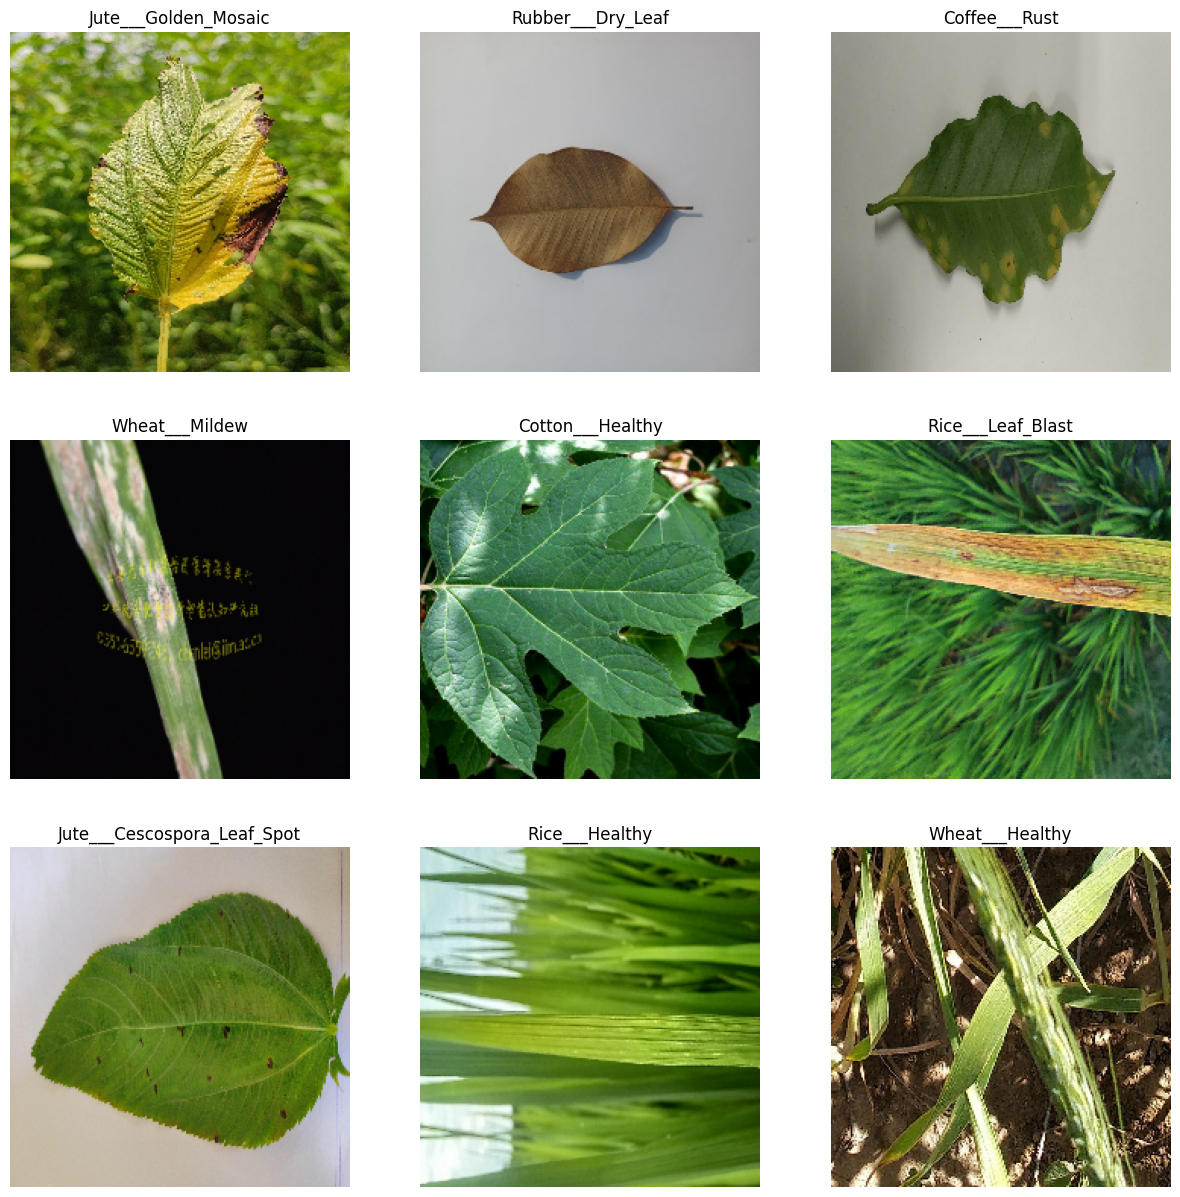

In [9]:
plt.figure(figsize=(15,15))
for images, labels in dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.title(class_names[labels[i]])
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.axis('off')


**Train-Test Split**

In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras import regularizers
from sklearn.utils.class_weight import compute_class_weight
# import splitfolders
import os

In [11]:
# # # Split dataset into train/val/test (if not already split)
# splitfolders.ratio(
#     'crop_images', 
#     output='dataset',
#     seed=42,
#     ratio=(.7, .2, .1)
# )

In [12]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    'dataset/train',
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    'dataset/val',
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    'dataset/test',
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 29323 files belonging to 59 classes.
Found 8366 files belonging to 59 classes.
Found 4236 files belonging to 59 classes.


In [13]:
class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)

Classes: ['Coffee___Healthy', 'Coffee___Miner', 'Coffee___Phoma', 'Coffee___Rust', 'Cotton___Aphids', 'Cotton___Army_Worm', 'Cotton___Bacterial_Blight', 'Cotton___Healthy', 'Cotton___Powdery_Mildew', 'Cotton___Target_Spot', 'Jute___Cescospora_Leaf_Spot', 'Jute___Golden_Mosaic', 'Jute___Healthy', 'Maize___Blight', 'Maize___Common_Rust', 'Maize___Gray_Leaf_Spot', 'Maize___Healthy', 'Potato___Early_Blight', 'Potato___Healthy', 'Potato___Late_Blight', 'Potato___Leafroll_Virus', 'Potato___Mosaic_Virus', 'Rice___Bacterial_Leaf_Blight', 'Rice___Brown_Spot', 'Rice___Healthy', 'Rice___Leaf_Blast', 'Rice___Leaf_scald', 'Rice___Sheath_Blight', 'Rubber___Anthracnose', 'Rubber___Dry_Leaf', 'Rubber___Healthy', 'Rubber___Leaf_Spot', 'Sugarcane___Healthy', 'Sugarcane___Mosaic', 'Sugarcane___Red_Rot', 'Sugarcane___Rust', 'Sugarcane___Yellow', 'Tea___Algal_Leaf_Spot', 'Tea___Brown_Blight', 'Tea___Gray_Blight', 'Tea___Green_Mirid_Bug', 'Tea___Healthy', 'Tea___Helopeltis', 'Tea___Red_spider', 'Wheat___Aph

In [14]:
# Performance optimizations by fetching the next batch into the cache
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [15]:
# Data augmentation layer
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2)
])

In [ ]:
for images, labels in train_ds.take(1):
    original_images = images[:9]   # take 9 images

# Apply augmentation to each image
augmented_images = [data_augmentation(img) for img in original_images]

# Plot augmented images
plt.figure(figsize=(12,12))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[i].numpy().astype("uint8"))
    plt.axis("off")

plt.suptitle("Example Augmented Images", fontsize=16)
plt.savefig("augmented_examples.png", dpi=300, bbox_inches='tight')
plt.show()


In [16]:
# Compute class weights=
all_labels = []
for _, y in train_ds.unbatch():
    all_labels.append(y.numpy())

all_labels = np.array(all_labels)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(num_classes),
    y=all_labels
)

class_weights = {int(i): float(w) for i, w in enumerate(class_weights)}
print("Class Weights:", class_weights)

Class Weights: {0: 1.775, 1: 1.5434782608695652, 2: 1.470414201183432, 3: 2.21875, 4: 0.8875, 5: 0.8875, 6: 0.8875, 7: 0.8875, 8: 0.8875, 9: 0.9019963702359347, 10: 2.300925925925926, 11: 2.053719008264463, 12: 2.7010869565217392, 13: 0.6197007481296758, 14: 0.5437636761487965, 15: 1.2394014962593516, 16: 0.6113161131611317, 17: 0.71, 18: 2.485, 19: 0.71, 20: 1.3505434782608696, 21: 1.0665236051502145, 22: 1.1168539325842697, 23: 1.0995575221238938, 24: 1.087527352297593, 25: 1.1218961625282167, 26: 1.132118451025057, 27: 1.1244343891402715, 28: 2.3666666666666667, 29: 1.5777777777777777, 30: 1.4039548022598871, 31: 1.470414201183432, 32: 1.3616438356164384, 33: 1.5386996904024768, 34: 1.37292817679558, 35: 1.384401114206128, 36: 1.4079320113314449, 37: 1.702054794520548, 38: 1.4039548022598871, 39: 0.7009873060648801, 40: 0.5540691192865106, 41: 0.7599388379204893, 42: 1.1721698113207548, 43: 1.3805555555555555, 44: 0.7729393468118196, 45: 1.1918465227817745, 46: 1.0688172043010753, 4

*MobileNetV3*

In [43]:
# Build Model: MobileNetV3 Transfer Learning
base_model = tf.keras.applications.MobileNetV3Large(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Freeze base initially

inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v3.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(
    256, activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)  # L2 regularization
)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)
model = models.Model(inputs, outputs)

In [44]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [45]:
# Callbacks
checkpoint = ModelCheckpoint(
    'models1/mobilenetv3_finetuned.h5', 
    monitor='val_accuracy', 
    save_best_only=True, 
    mode='max'
)

early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

In [46]:
model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 MobilenetV3large (Functiona  (None, 7, 7, 960)        2996352   
 l)                                                              
                                                                 
 global_average_pooling2d_1   (None, 960)              0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dropout_1 (Dropout)         (None, 960)               0         
                                                                 
 dense_2 (Dense)             (None, 256)               2460

In [47]:
# Train top layers first
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop]
)

Epoch 1/20
 21/917 [..............................] - ETA: 6:49 - loss: 4.3856 - accuracy: 0.0670

KeyboardInterrupt: 

In [26]:
history.params

{'verbose': 1, 'epochs': 100, 'steps': 917}

In [27]:
history.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [ ]:
accuracy = []
val_accuracy = []

loss = []
val_loss = []

In [58]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam

# Load the saved model for mobilenetv3-small from checkpoint
model = load_model("models1/mobilenetv3_finetuned.h5")

# Find the MobileNetV3 base inside your model - MobileNet is a nested model
for layer in model.layers:
    if isinstance(layer, tf.keras.Model):  
        base_model = layer
        break

# Example: Unfreeze last N layers
for layer in base_model.layers[-30:]:
    layer.trainable = True

# Keep earlier layers frozen
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with small LR
model.compile(
    optimizer=Adam(learning_rate=1e-5),  
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop]  
)


Epoch 1/20
917/917 [==============================] - 2023s 2s/step - loss: 0.5861 - accuracy: 0.8251 - val_loss: 0.5470 - val_accuracy: 0.8521
Epoch 2/20
917/917 [==============================] - 1283s 1s/step - loss: 0.5937 - accuracy: 0.8244 - val_loss: 0.5470 - val_accuracy: 0.8527
Epoch 3/20
917/917 [==============================] - 932s 1s/step - loss: 0.5910 - accuracy: 0.8218 - val_loss: 0.5465 - val_accuracy: 0.8527
Epoch 4/20
917/917 [==============================] - 560s 611ms/step - loss: 0.5922 - accuracy: 0.8221 - val_loss: 0.5477 - val_accuracy: 0.8529
Epoch 5/20
917/917 [==============================] - 476s 520ms/step - loss: 0.5877 - accuracy: 0.8246 - val_loss: 0.5462 - val_accuracy: 0.8525
Epoch 6/20
917/917 [==============================] - 838s 914ms/step - loss: 0.5950 - accuracy: 0.8193 - val_loss: 0.5462 - val_accuracy: 0.8520
Epoch 7/20
917/917 [==============================] - 888s 968ms/step - loss: 0.5907 - accuracy: 0.8237 - val_loss: 0.5467 - val_ac

In [59]:
history_fine.params

{'verbose': 1, 'epochs': 20, 'steps': 917}

In [60]:
history_fine.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [61]:
history_fine.history['accuracy']

[0.825120210647583,
 0.8244040608406067,
 0.8218122124671936,
 0.822050929069519,
 0.8246427774429321,
 0.8193227052688599,
 0.8236879110336304,
 0.8240630030632019,
 0.8240630030632019,
 0.823585569858551,
 0.8223578929901123,
 0.8223237991333008,
 0.8222214579582214,
 0.8237560987472534,
 0.8208232522010803,
 0.8232786655426025,
 0.826654851436615,
 0.8258022665977478,
 0.8257340788841248,
 0.8248814940452576]

*MobileNet Evaluation*

In [62]:
# Evaluate on Test Data
from keras.models import load_model
# model = load_model('models/mobilenetv3_retrain.h5')
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}, {test_loss}")

133/133 [==============================] - 19s 146ms/step - loss: 0.5640 - accuracy: 0.8428
Test Accuracy: 84.28, 0.5639988780021667


In [63]:
# Save final model
model.save('models1/mobilenetv3_finetuned.h5')

In [64]:
accuracy1 = history_fine.history['accuracy']
val_accuracy1 = history_fine.history['val_accuracy']

loss1 = history_fine.history['loss']
val_loss1 = history_fine.history['val_loss']

In [65]:


accuracy += accuracy1
val_accuracy += val_accuracy1

loss += loss1
val_loss += val_loss1

epochs = len(accuracy)

In [66]:
accuracy

[0.8208573460578918,
 0.8208914399147034,
 0.8237220048904419,
 0.8212665915489197,
 0.8214712142944336,
 0.8209255337715149,
 0.8232786655426025,
 0.8202434778213501,
 0.818845272064209,
 0.8212665915489197,
 0.825120210647583,
 0.8244040608406067,
 0.8218122124671936,
 0.822050929069519,
 0.8246427774429321,
 0.8193227052688599,
 0.8236879110336304,
 0.8240630030632019,
 0.8240630030632019,
 0.823585569858551,
 0.8223578929901123,
 0.8223237991333008,
 0.8222214579582214,
 0.8237560987472534,
 0.8208232522010803,
 0.8232786655426025,
 0.826654851436615,
 0.8258022665977478,
 0.8257340788841248,
 0.8248814940452576]

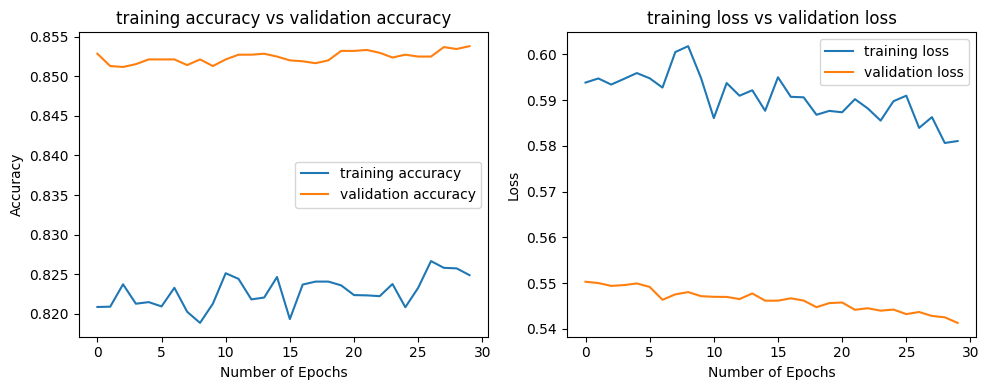

In [67]:
# for last 10 epochs
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(epochs), accuracy, label="training accuracy")
plt.plot(range(epochs), val_accuracy, label="validation accuracy")
plt.title("training accuracy vs validation accuracy")
plt.xlabel("Number of Epochs")
plt.ylabel("Accuracy")
plt.legend()
# plt.ylim(0.86, 0.96)


plt.subplot(1, 2, 2)
plt.plot(range(epochs), loss, label="training loss")
plt.plot(range(epochs), val_loss, label="validation loss")
plt.title("training loss vs validation loss")
plt.xlabel("Number of Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

*ResNet50*

In [73]:
# Build Model: ResNet50 Transfer Learning
base_model = tf.keras.applications.ResNet50(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Freeze base initially

inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(
    256, activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)  # L2 regularization
)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)
model = models.Model(inputs, outputs)

In [74]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [75]:
# Callbacks
checkpoint = ModelCheckpoint(
    'models1/resnet50_finetuned.h5', 
    monitor='val_accuracy', 
    save_best_only=True, 
    mode='max'
)

early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

In [76]:
# Train top layers first
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop]
)

Epoch 1/100
917/917 [==============================] - 690s 741ms/step - loss: 1.3850 - accuracy: 0.5963 - val_loss: 0.8318 - val_accuracy: 0.7483
Epoch 2/100
917/917 [==============================] - 504s 550ms/step - loss: 0.9445 - accuracy: 0.7058 - val_loss: 0.8638 - val_accuracy: 0.7446
Epoch 3/100
917/917 [==============================] - 690s 752ms/step - loss: 0.8829 - accuracy: 0.7265 - val_loss: 0.7020 - val_accuracy: 0.7984
Epoch 4/100
917/917 [==============================] - 600s 654ms/step - loss: 0.8516 - accuracy: 0.7395 - val_loss: 0.7525 - val_accuracy: 0.7844
Epoch 5/100
917/917 [==============================] - 457s 499ms/step - loss: 0.8296 - accuracy: 0.7489 - val_loss: 0.7652 - val_accuracy: 0.7805
Epoch 6/100
917/917 [==============================] - 460s 501ms/step - loss: 0.8137 - accuracy: 0.7595 - val_loss: 0.7698 - val_accuracy: 0.7881


In [78]:
accuracy = []
val_accuracy = []

loss = []
val_loss = []

In [118]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam

# Load the saved model for resnet50
model = load_model("models1/resnet50_finetuned.h5")

base_model = model.get_layer('resnet50')   # fetches base model from where your pretrained base is

# Unfreeze last N layers
for layer in base_model.layers[-60:]:  
    layer.trainable = True

# Keep earlier layers frozen
for layer in base_model.layers[:-60]:
    layer.trainable = False


# Recompile with small LR
model.compile(
    optimizer=Adam(learning_rate=1e-5), 
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Fine-Tuning
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop]
)


Epoch 1/20
138/917 [===>..........................] - ETA: 9:54 - loss: 0.2112 - accuracy: 0.9493

KeyboardInterrupt: 

*ResNet50 Evaluation*

In [115]:
model = tf.keras.models.load_model("models1/resnet50_finetuned.h5")

In [116]:
# Evaluate on Test Data
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}, {test_loss}")

133/133 [==============================] - 24s 170ms/step - loss: 0.4143 - accuracy: 0.9013
Test Accuracy: 90.13, 0.4142695963382721


In [117]:
# Save final model
model.save('models1/resnet50_finetuned.keras')

In [108]:
history_fine.params

{'verbose': 1, 'epochs': 20, 'steps': 917}

In [109]:
history_fine.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [110]:
accuracy1 = history_fine.history['accuracy']
val_accuracy1 = history_fine.history['val_accuracy']

loss1 = history_fine.history['loss']
val_loss1 = history_fine.history['val_loss']

In [111]:
accuracy += accuracy1
val_accuracy += val_accuracy1

loss += loss1
val_loss += val_loss1

epochs = len(accuracy)

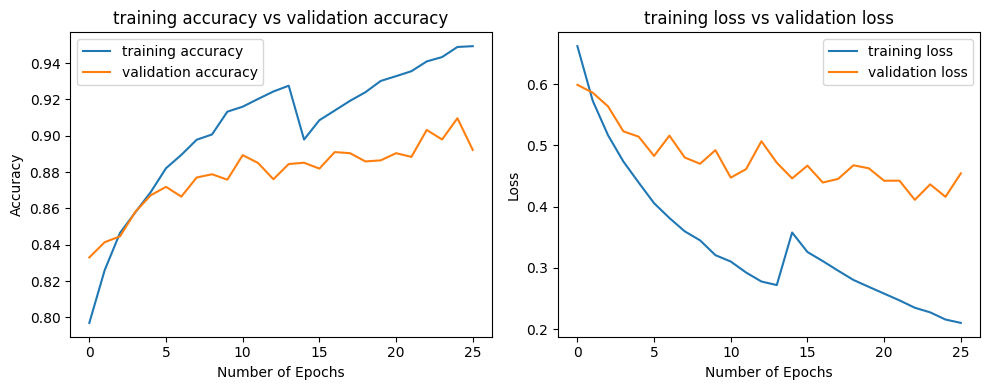

In [112]:
# for last 10 epochs
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(epochs), accuracy, label="training accuracy")
plt.plot(range(epochs), val_accuracy, label="validation accuracy")
plt.title("training accuracy vs validation accuracy")
plt.xlabel("Number of Epochs")
plt.ylabel("Accuracy")
plt.legend()
# plt.ylim(0.86, 0.96)


plt.subplot(1, 2, 2)
plt.plot(range(epochs), loss, label="training loss")
plt.plot(range(epochs), val_loss, label="validation loss")
plt.title("training loss vs validation loss")
plt.xlabel("Number of Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

**Prediction**

In [40]:
def predict(model, img):
    # pass a numpy image
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = np.round(100 * max(predictions[0]), 2)

    return predicted_class, confidence

1/1 [==============================] - 0s 64ms/step


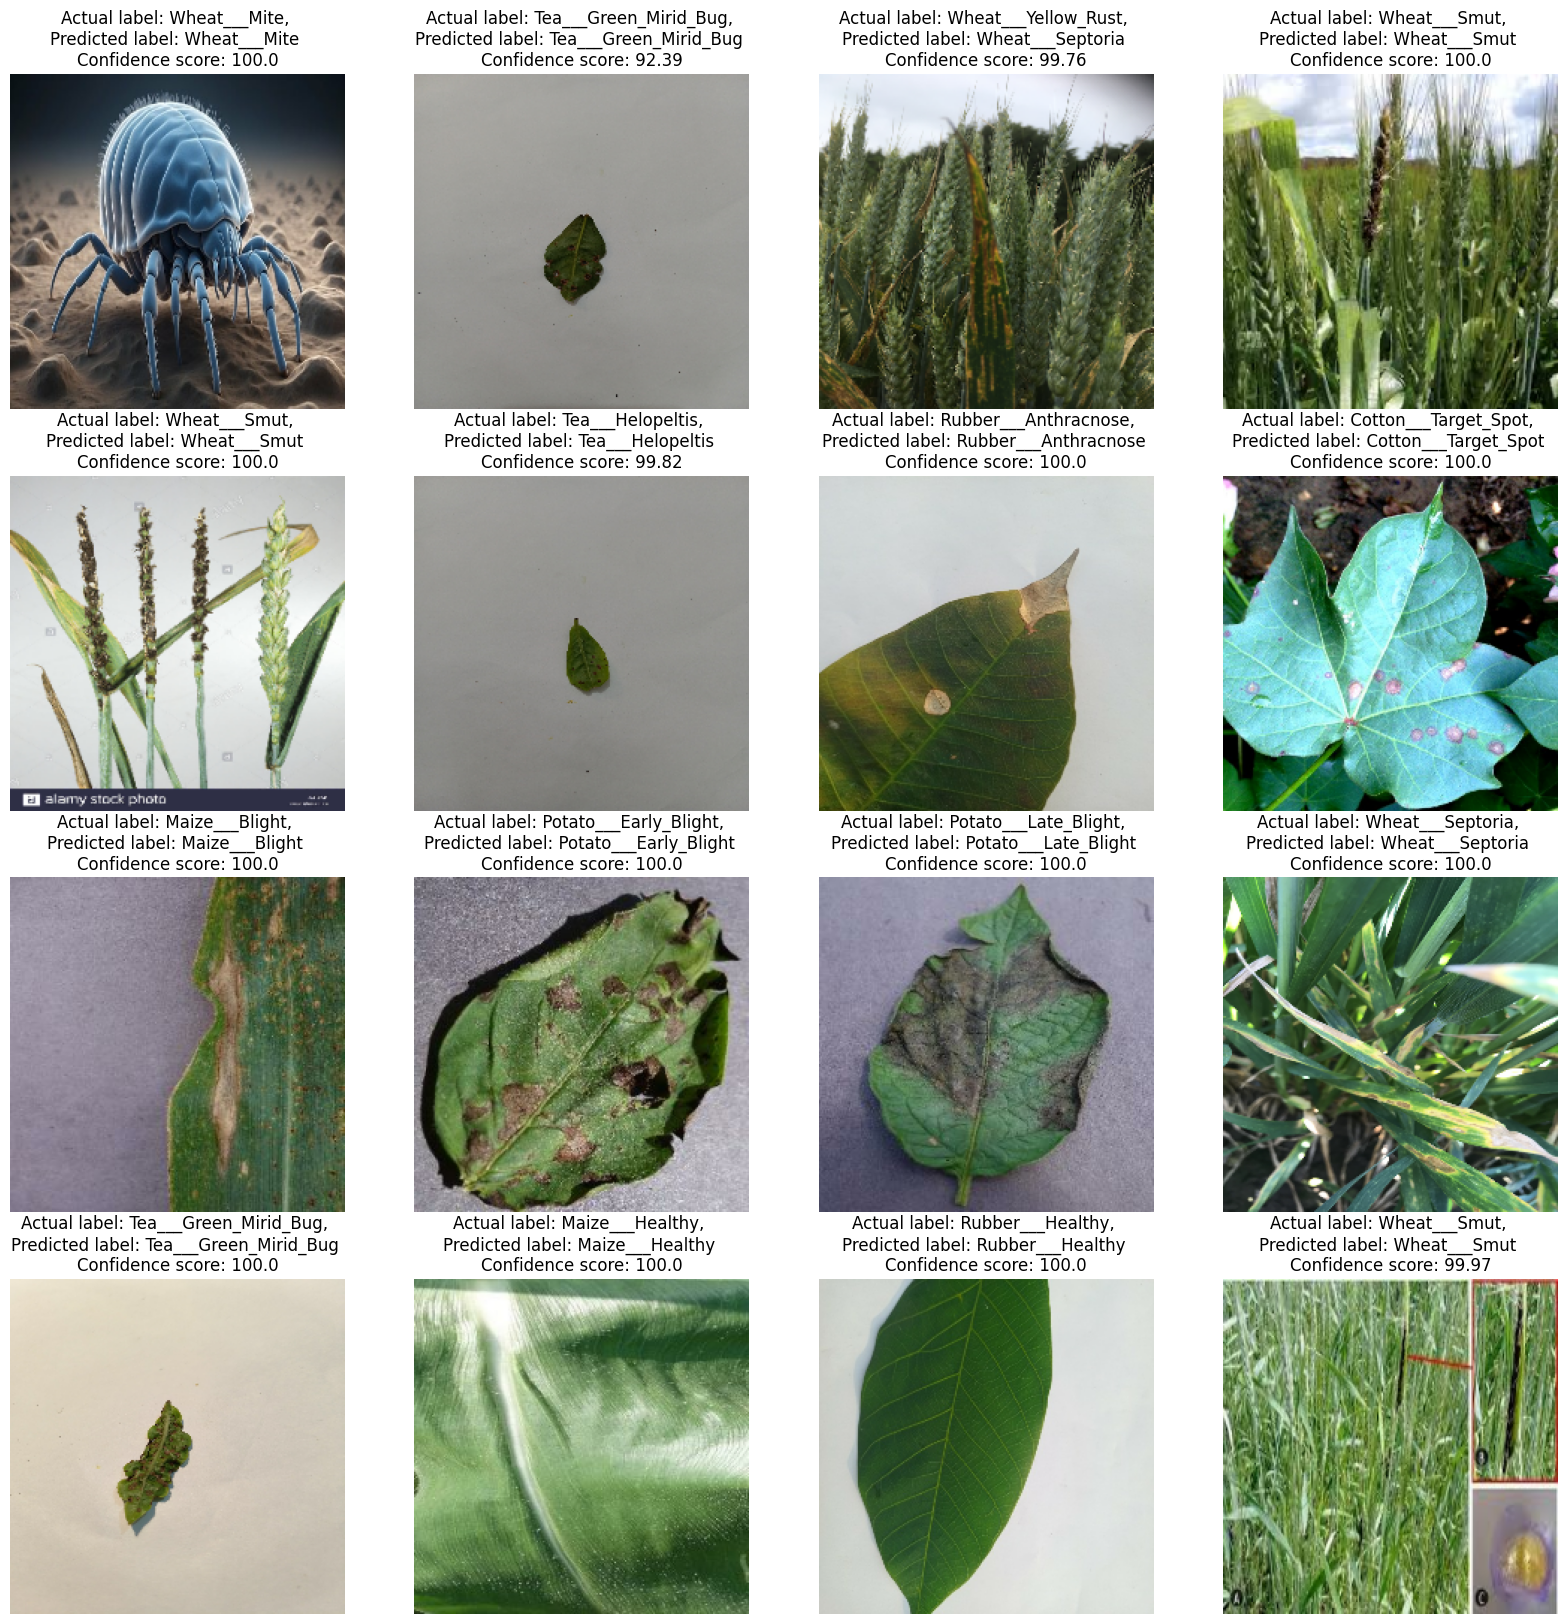

In [56]:
plt.figure(figsize=(20, 20))
for images, labels in test_ds.take(1):
    for i in range(16):
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))

        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]

        plt.title(f"Actual label: {actual_class}, \nPredicted label: {predicted_class} \nConfidence score: {confidence}")
        plt.axis('off')